# Weather Enrichment

### Import libraries

In [53]:
# Set up the import for API
import openmeteo_requests

import pandas as pd
import requests_cache
from retry_requests import retry

# Imports for visualizations
import matplotlib.pyplot as plt

### Set up API to import the data

In [54]:
host = "archive-api.open-meteo.com"
url = f"https://{host}/v1/archive"

params = {
    "latitude": 40.7143,
    "longitude": -74.006,
    "start_date": "2026-01-01",
    "end_date": "2026-01-31",
    "hourly": [
        "temperature_2m",
        "precipitation",
        "rain",
        "snowfall",
        "wind_speed_10m"
    ],
    "timezone": "America/New_York",
    "temperature_unit": "fahrenheit",
    "wind_speed_unit": "mph",
    "precipitation_unit": "inch"
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

data = response.json()

hourly_dataframe = pd.DataFrame(data["hourly"])

hourly_dataframe = hourly_dataframe.rename(
    columns={"time": "date"}
)

hourly_dataframe["date"] = pd.to_datetime(
    hourly_dataframe["date"]
)

In [55]:
hourly_dataframe.head(10)

,date,temperature_2m,precipitation,rain,snowfall,wind_speed_10m
0,2026-01-01 00:00:00,30.2,0.000,0.0,0.000,8.1
1,2026-01-01 01:00:00,30.6,0.004,0.0,0.028,8.1
2,2026-01-01 02:00:00,31.3,0.004,0.0,0.028,8.3
3,2026-01-01 03:00:00,31.7,0.000,0.0,0.000,8.3
4,2026-01-01 04:00:00,32.7,0.000,0.0,0.000,8.7
5,2026-01-01 05:00:00,33.2,0.000,0.0,0.000,9.5
6,2026-01-01 06:00:00,32.8,0.000,0.0,0.000,9.2
7,2026-01-01 07:00:00,32.2,0.008,0.0,0.055,10.2
8,2026-01-01 08:00:00,27.5,0.028,0.0,0.193,13.1
9,2026-01-01 09:00:00,24.7,0.000,0.0,0.000,13.2


In [56]:
hourly_dataframe.shape

(744, 6)

In [57]:
assert len(hourly_dataframe) == 744

assert hourly_dataframe["date"].iloc[0] == pd.Timestamp(
    "2026-01-01 00:00:00"
)

assert hourly_dataframe["date"].iloc[-1] == pd.Timestamp(
    "2026-01-31 23:00:00"
)

assert (
    hourly_dataframe["date"]
    .diff()
    .dropna()
    .eq(pd.Timedelta(hours=1))
    .all()
)

### Export the data

In [58]:
# Exporting the data
hourly_dataframe.to_csv('../data/raw/nyc_weather_hourly.csv', index=False)

### Preview the data

In [59]:
hourly_dataframe.head()

,date,temperature_2m,precipitation,rain,snowfall,wind_speed_10m
0,2026-01-01 00:00:00,30.2,0.000,0.0,0.000,8.1
1,2026-01-01 01:00:00,30.6,0.004,0.0,0.028,8.1
2,2026-01-01 02:00:00,31.3,0.004,0.0,0.028,8.3
3,2026-01-01 03:00:00,31.7,0.000,0.0,0.000,8.3
4,2026-01-01 04:00:00,32.7,0.000,0.0,0.000,8.7


In [60]:
hourly_dataframe.columns.tolist()

['date',
 'temperature_2m',
 'precipitation',
 'rain',
 'snowfall',
 'wind_speed_10m']

## Data Dictionary

|Variable|Unit|Description|
|--------|----|-----------|
|date|hourly|The time upon when the observation is recorded.|
|temperature_2m|°F|Air temperature at 2 meters above ground|
|precipitation|inch|Total precipitation (rain, showers, snow) sum of the preceding hour.|
|rain|inch|Rain from large scale weather systems of the preceding hour in millimeter|
|snowfall|inch|Snowfall amount of the preceding hour in inches.|
|wind_speed_10m|mph|Wind direction at 10 meters above ground.|

### Some visualizations to make the data look clear

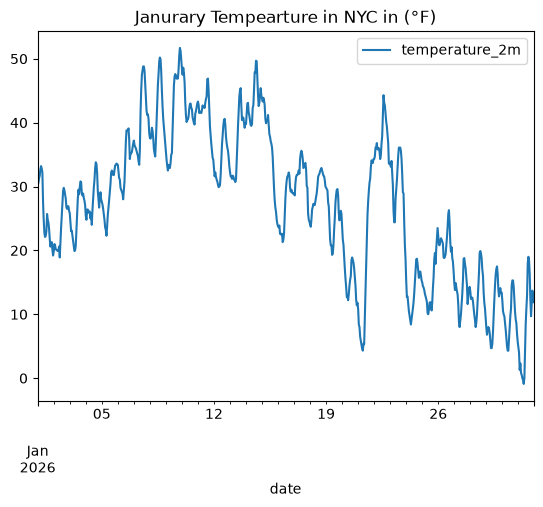

In [61]:
hourly_dataframe.plot(x='date', y=['temperature_2m'], kind='line', title='Janurary Tempearture in NYC in (°F)')
plt.show()

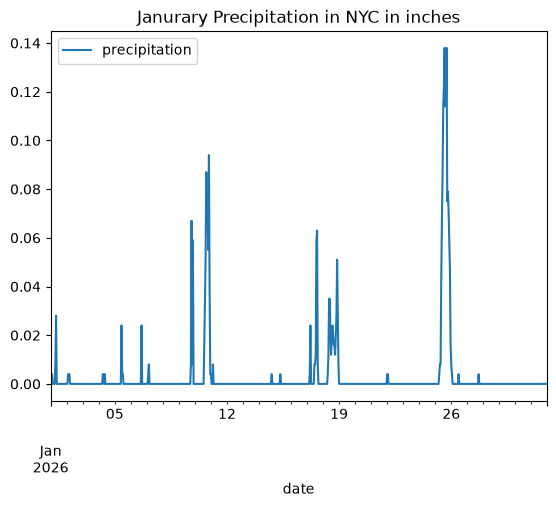

In [62]:
hourly_dataframe.plot(x='date', y=['precipitation'], kind='line', title='Janurary Precipitation in NYC in inches')
plt.show()

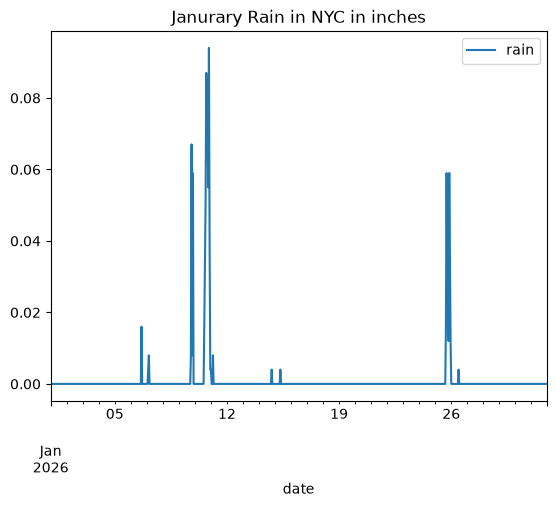

In [63]:
hourly_dataframe.plot(x='date', y=['rain'], kind='line', title='Janurary Rain in NYC in inches')
plt.show()

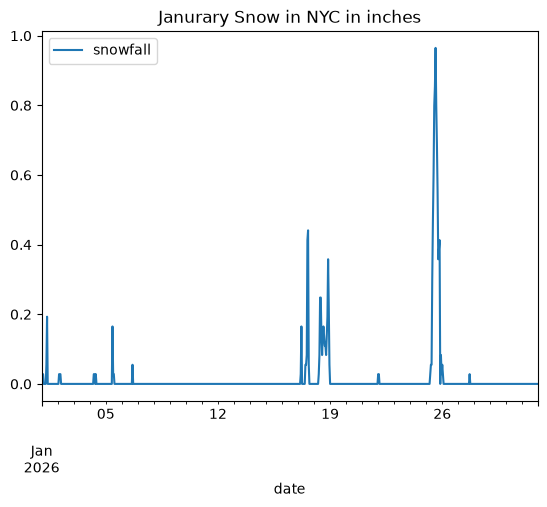

In [64]:
hourly_dataframe.plot(x='date', y=['snowfall'], kind='line', title='Janurary Snow in NYC in inches')
plt.show()

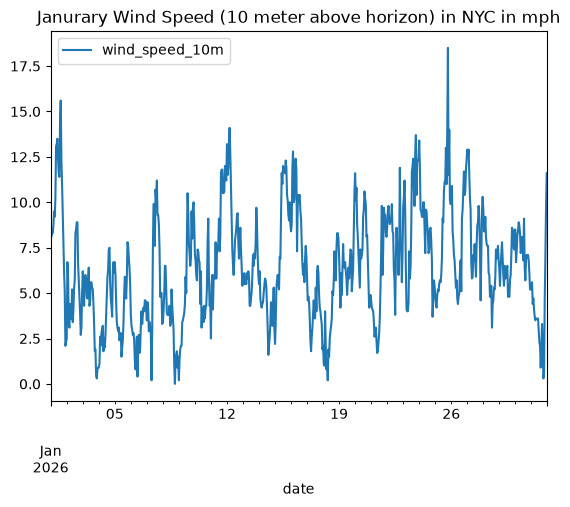

In [65]:
hourly_dataframe.plot(x='date', y=['wind_speed_10m'], kind='line', title='Janurary Wind Speed (10 meter above horizon) in NYC in mph')
plt.show()